# Module 11 Assignment: SQL and Relational Data
**CS 5045: Computation for the Data Sciences**

**Name:** Brian A. Thomas

---

Complete each section by filling in the blanks marked `__________` or writing answers where indicated. Section 5 (Code From Scratch) has no blanks; you write the full query yourself.
Run all cells top to bottom and confirm there are no errors before submitting.
Commit and push this notebook (`hw11.ipynb`) to your fork on GitHub, no Canvas upload needed.

**Libraries needed:** sqlite3 (built into Python, no install required), pandas, matplotlib.

**Also needed:** the local C compiler you set up for Seminar 3 (Section 7).

## Section 1: Setup -- Create the In-Memory Database

Both tables are created inline in this notebook. There is no external file to load.
Run this cell first. It creates the database, both tables, and inserts all the data.
You will use the `conn` object in every section below.

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

# Create an in-memory SQLite database.
# ':memory:' means the database lives in RAM only -- gone when Python exits.
conn = sqlite3.connect(':memory:')

# Create the customers table.
conn.execute('''
    CREATE TABLE customers (
        customer_id  INTEGER PRIMARY KEY,
        name         TEXT,
        state        TEXT,
        total_spent  REAL,
        year         INTEGER
    )
''')

# Create the orders table.
# customer_id here is a foreign key referencing the customers table.
conn.execute('''
    CREATE TABLE orders (
        order_id     INTEGER PRIMARY KEY,
        customer_id  INTEGER REFERENCES customers,
        product      TEXT,
        amount       REAL
    )
''')

# Insert 15 customers.
customers_data = [
    (1,  'Alice Chen',    'CA', 1250.00, 2021),
    (2,  'Bob Martin',    'TX',  480.00, 2022),
    (3,  'Carmen Lopez',  'CA',  895.50, 2020),
    (4,  'David Kim',     'NY', 2300.00, 2021),
    (5,  'Emma Walsh',    'CA',  320.00, 2023),
    (6,  'Frank Osei',    'TX', 1750.00, 2020),
    (7,  'Grace Park',    'NY',  640.00, 2022),
    (8,  'Henry Brown',   'FL',  890.00, 2021),
    (9,  'Isabel Torres', 'CA', 1100.00, 2022),
    (10, 'James Wilson',  'TX',  250.00, 2023),
    (11, 'Karen Adams',   'NY', 3100.00, 2020),
    (12, 'Luis Rivera',   'FL',  700.00, 2021),
    (13, 'Maya Patel',    'CA',  550.00, 2022),
    (14, 'Noah Clark',    'NY',  980.00, 2021),
    (15, 'Olivia Scott',  'FL', 1400.00, 2020),
]
conn.executemany(
    'INSERT INTO customers VALUES (?, ?, ?, ?, ?)',
    customers_data
)

# Insert 12 orders.
# Note: not every customer has an order -- this matters for the JOIN section.
orders_data = [
    (101, 1,  'Laptop',      999.00),
    (102, 1,  'Mouse',        45.00),
    (103, 3,  'Keyboard',     89.50),
    (104, 4,  'Monitor',     650.00),
    (105, 4,  'Webcam',      120.00),
    (106, 6,  'Headphones',  250.00),
    (107, 7,  'USB Hub',      35.00),
    (108, 8,  'Desk Lamp',    75.00),
    (109, 9,  'Tablet',      520.00),
    (110, 11, 'Laptop',     1100.00),
    (111, 11, 'Printer',     299.00),
    (112, 14, 'Microphone',  185.00),
]
conn.executemany(
    'INSERT INTO orders VALUES (?, ?, ?, ?)',
    orders_data
)

conn.commit()
print('Database ready: customers (15 rows), orders (12 rows)')

Database ready: customers (15 rows), orders (12 rows)


## Section 2: Basic Queries

Each cell below contains a SQL query with one or more blanks.
Fill in the blanks so the query does what the comment describes.
Run each cell and read the output before moving on.

### Section 2a: SELECT -- Show All Customers

In [5]:
# 2a. Select all columns from the customers table and return all 15 rows.
#     Fill in the column selector (use * for all columns) and the table name.

query_2a = '''
    SELECT *
    FROM customers
    ORDER BY name
'''

rows = conn.execute(query_2a).fetchall()
print(f'Rows returned: {len(rows)}')
for row in rows:
    print(row)

# Expected: 15 rows, each tuple is (customer_id, name, state, total_spent, year)

Rows returned: 15
(1, 'Alice Chen', 'CA', 1250.0, 2021)
(2, 'Bob Martin', 'TX', 480.0, 2022)
(3, 'Carmen Lopez', 'CA', 895.5, 2020)
(4, 'David Kim', 'NY', 2300.0, 2021)
(5, 'Emma Walsh', 'CA', 320.0, 2023)
(6, 'Frank Osei', 'TX', 1750.0, 2020)
(7, 'Grace Park', 'NY', 640.0, 2022)
(8, 'Henry Brown', 'FL', 890.0, 2021)
(9, 'Isabel Torres', 'CA', 1100.0, 2022)
(10, 'James Wilson', 'TX', 250.0, 2023)
(11, 'Karen Adams', 'NY', 3100.0, 2020)
(12, 'Luis Rivera', 'FL', 700.0, 2021)
(13, 'Maya Patel', 'CA', 550.0, 2022)
(14, 'Noah Clark', 'NY', 980.0, 2021)
(15, 'Olivia Scott', 'FL', 1400.0, 2020)


### Section 2b: WHERE -- Filter by State and Spending

In [7]:
# 2b. Select name, state, and total_spent for customers in California (state = 'CA')
#     whose total_spent is greater than 800.
#     Fill in the two missing column names in the SELECT list
#     and the two WHERE conditions.
#customer_id, name, state, total_spent, year
query_2b = '''
    SELECT name, state, total_spent
    FROM customers
    WHERE state = 'CA'
      AND total_spent > 800
'''

rows = conn.execute(query_2b).fetchall()
print('California customers with total_spent > 800:')
for row in rows:
    print(row)

# Expected output (3 rows):
# ('Alice Chen', 'CA', 1250.0)
# ('Carmen Lopez', 'CA', 895.5)
# ('Isabel Torres', 'CA', 1100.0)

California customers with total_spent > 800:
('Alice Chen', 'CA', 1250.0)
('Carmen Lopez', 'CA', 895.5)
('Isabel Torres', 'CA', 1100.0)


### Section 2c: ORDER BY and LIMIT -- Top Spenders

In [9]:
# 2c. Select name, state, and total_spent for all customers.
#     Sort by total_spent from highest to lowest.
#     Return only the top 5 rows.
#     Fill in the column to sort on, the sort direction (DESC), and the row limit.

query_2c = '''
    SELECT name, state, total_spent
    FROM customers
    ORDER BY total_spent DESC
    LIMIT 5
'''

rows = conn.execute(query_2c).fetchall()
print('Top 5 customers by spending:')
for row in rows:
    print(row)

# Expected output (descending by total_spent):
# ('Karen Adams', 'NY', 3100.0)
# ('David Kim', 'NY', 2300.0)
# ('Frank Osei', 'TX', 1750.0)
# ('Olivia Scott', 'FL', 1400.0)
# ('Alice Chen', 'CA', 1250.0)

Top 5 customers by spending:
('Karen Adams', 'NY', 3100.0)
('David Kim', 'NY', 2300.0)
('Frank Osei', 'TX', 1750.0)
('Olivia Scott', 'FL', 1400.0)
('Alice Chen', 'CA', 1250.0)


## Section 3: Aggregation in SQL

GROUP BY collapses many rows into one summary row per group.
HAVING filters those group-level summaries after aggregation runs.

### Section 3a: GROUP BY with COUNT

In [10]:
# 3a. Count how many customers are in each state.
#     Return state and the count, labeled as num_customers.
#     Sort by num_customers descending.
#     Fill in: the aggregate function name, its argument (*), and the grouping column.

query_3a = '''
    SELECT state,
           count(name) AS num_customers
    FROM customers
    GROUP BY state
    ORDER BY num_customers DESC
'''

rows = conn.execute(query_3a).fetchall()
print('Customers per state:')
for row in rows:
    print(row)

# Expected output:
# ('CA', 5)
# ('NY', 4)
# ('FL', 3)
# ('TX', 3)

Customers per state:
('CA', 5)
('NY', 4)
('TX', 3)
('FL', 3)


### Section 3b: GROUP BY with AVG

In [12]:
# 3b. Compute the average order amount for each product in the orders table.
#     Return product and the average amount, labeled as avg_amount.
#     Sort by avg_amount descending.
#     Fill in the blank: the SQL aggregate function for average.

query_3b = '''
    SELECT product,
           avg(amount) AS avg_amount
    FROM orders
    GROUP BY product
    ORDER BY avg_amount DESC
'''

rows = conn.execute(query_3b).fetchall()
print('Average order amount by product:')
for row in rows:
    print(f'{row[0]:<15}  ${row[1]:.2f}')

# Note: Laptop appears twice (orders 101 and 110), so its avg = (999 + 1100) / 2 = 1049.50
# Expected top entries:
# Laptop           $1049.50
# Monitor          $650.00
# Tablet           $520.00

Average order amount by product:
Laptop           $1049.50
Monitor          $650.00
Tablet           $520.00
Printer          $299.00
Headphones       $250.00
Microphone       $185.00
Webcam           $120.00
Keyboard         $89.50
Desk Lamp        $75.00
Mouse            $45.00
USB Hub          $35.00


### Section 3c: HAVING -- Filter After Aggregation

In [16]:
# 3c. Find states that have MORE THAN 3 customers.
#     Return state and the customer count, labeled as num_customers.
#     Fill in the HAVING clause condition using COUNT(*).
#     Reminder: HAVING filters groups; WHERE filters individual rows.

query_3c = '''
    SELECT state,
           COUNT(*) AS num_customers
    FROM customers
    GROUP BY state
    HAVING count(*) > 3
'''

rows = conn.execute(query_3c).fetchall()
print('States with more than 3 customers:')
for row in rows:
    print(row)

# Expected output (only CA and NY qualify):
# ('CA', 5)
# ('NY', 4)

States with more than 3 customers:
('CA', 5)
('NY', 4)


## Section 4: Joining Tables

An INNER JOIN combines rows from two tables on a shared key.
Only rows with a matching key value in both tables appear in the result.

### Section 4a: INNER JOIN

In [20]:
# 4a. Join the customers and orders tables.
#     Return customer name, state, product, and order amount.
#     Sort by customer name.
#     Fill in the join type (INNER) and the ON condition.

query_4a = '''
    SELECT customers.name,
           customers.state,
           orders.product,
           orders.amount
    FROM customers
    INNER JOIN orders
      ON customers.customer_id = orders.customer_id
    ORDER BY customers.name
'''

rows = conn.execute(query_4a).fetchall()
print(f'Rows returned: {len(rows)}')
print('name, state, product, amount:')
for row in rows:
    print(row)

# Expected: 12 rows (one per order, not per customer).
# Customers with no orders do not appear (Bob Martin, Emma Walsh, etc.).
# Alice Chen appears twice: one row for Laptop, one for Mouse.
# Karen Adams appears twice: one row for Laptop, one for Printer.

Rows returned: 12
name, state, product, amount:
('Alice Chen', 'CA', 'Laptop', 999.0)
('Alice Chen', 'CA', 'Mouse', 45.0)
('Carmen Lopez', 'CA', 'Keyboard', 89.5)
('David Kim', 'NY', 'Monitor', 650.0)
('David Kim', 'NY', 'Webcam', 120.0)
('Frank Osei', 'TX', 'Headphones', 250.0)
('Grace Park', 'NY', 'USB Hub', 35.0)
('Henry Brown', 'FL', 'Desk Lamp', 75.0)
('Isabel Torres', 'CA', 'Tablet', 520.0)
('Karen Adams', 'NY', 'Laptop', 1100.0)
('Karen Adams', 'NY', 'Printer', 299.0)
('Noah Clark', 'NY', 'Microphone', 185.0)


### Section 4b: GROUP BY on a Joined Table

In [22]:
# 4b. Join customers and orders, then aggregate:
#     compute the total amount each customer spent across all their orders.
#     Return customer name and total order amount, labeled as order_total.
#     Sort by order_total descending.
#     Fill in the blanks: the aggregate function for sum and the grouping column.

query_4b = '''
    SELECT customers.name,
           sum (orders.amount) AS order_total
    FROM customers
    INNER JOIN orders
      ON customers.customer_id = orders.customer_id
    GROUP BY customers.name
    ORDER BY order_total DESC
'''

rows = conn.execute(query_4b).fetchall()
print('Total order amount per customer:')
for row in rows:
    print(f'{row[0]:<16}  ${row[1]:.2f}')

# Expected output (9 customers who have at least one order):
# Karen Adams      $1399.00   (Laptop 1100 + Printer 299)
# Alice Chen       $1044.00   (Laptop 999 + Mouse 45)
# David Kim        $770.00    (Monitor 650 + Webcam 120)
# Isabel Torres    $520.00
# Frank Osei       $250.00
# Noah Clark       $185.00
# Carmen Lopez     $89.50
# Henry Brown      $75.00
# Grace Park       $35.00

Total order amount per customer:
Karen Adams       $1399.00
Alice Chen        $1044.00
David Kim         $770.00
Isabel Torres     $520.00
Frank Osei        $250.00
Noah Clark        $185.00
Carmen Lopez      $89.50
Henry Brown       $75.00
Grace Park        $35.00


### Section 4c: pd.read_sql_query() -- SQL Results as a DataFrame

Result as a DataFrame:
  state  num_customers
0    CA              5
1    NY              4
2    TX              3
3    FL              3

Column types:
state              str
num_customers    int64
dtype: object


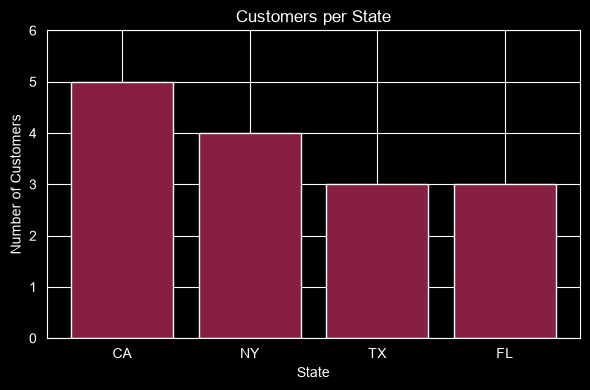

In [23]:
# 4c. Use pd.read_sql_query() to run the GROUP BY query from Section 3a
#     and load the result directly into a pandas DataFrame.
#     Then create a bar chart of the result.
#     Fill in the blank: the pandas function that takes (sql_string, conn)
#     and returns a DataFrame.

query_4c = '''
    SELECT state,
           COUNT(*) AS num_customers
    FROM customers
    GROUP BY state
    ORDER BY num_customers DESC
'''

# Run the SQL query and load the result into a DataFrame.
df = pd.read_sql_query(query_4c, conn)

print('Result as a DataFrame:')
print(df)
print()
print('Column types:')
print(df.dtypes)

# Plot: bar chart of customers per state.
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(df['state'], df['num_customers'], color='#861F41')
ax.set_xlabel('State')
ax.set_ylabel('Number of Customers')
ax.set_title('Customers per State')
ax.set_ylim(0, df['num_customers'].max() + 1)
plt.tight_layout()
plt.show()

# Expected: a 4-row DataFrame with columns 'state' and 'num_customers'.
# The bar chart shows CA with 5, NY with 4, FL and TX with 3 each.

---
## Section 5: Code From Scratch

No blanks this time. You get the question only, write the full query yourself. This composes two things you already did separately: JOIN (Section 4a/4b) and GROUP BY (Section 3a).

**Question:** Write a single SQL query that joins `customers` and `orders`, groups by `state`, and computes the total order amount per state. Which state has the highest total order amount? Is it the same state that has the most customers (Section 3a)?

In [27]:
# Write your own query below. No starter code or blanks are provided for this section.
#
# Join customers and orders, group by state, and sum the order amounts.
# Then identify which state has the highest total.
# Write your own query below. No starter code or blanks are provided for this section.
#
# Join customers and orders, group by state, and sum the order amounts.
# Then identify which state has the highest total.

query_4c = '''
    SELECT customers.state,
           SUM(orders.amount) AS state_total
    FROM customers
    INNER JOIN orders
      ON customers.customer_id = orders.customer_id
    GROUP BY customers.state
    ORDER BY state_total DESC
    LIMIT 1
'''

rows = conn.execute(query_4c).fetchall()
print('State with the highest total order amount:')
for row in rows:
    print(f'{row[0]} has the highest total order amount (${row[1]:,.2f})')





# SUM(orders.amount): Adds up all individual order amounts.
# GROUP BY customers.state: Combines individual customer rows into groups based on their state.
# ORDER BY state_total DESC: Places the highest spending state at the top of the results list.
# LIMIT 1: Keeps only the top row, isolating the state with the maximum total spending.


# Expected: NY has the highest total order amount ($2,389.00), even though
# CA has the most customers (5, from Section 3a). NY only has 4 customers.

State with the highest total order amount:
NY has the highest total order amount ($2,389.00)


**Reflection (one sentence):** CA has the most customers, but NY leads in total order amount. In one sentence, what does this tell you about the relationship between customer count and revenue?

**Your answer:**
The more customers a business has does not necessary mean they will have a higher revenue; a smaller count of customers can generate higher revenue based on the items purchased.

a## Section 6: Reflection

Answer each question in 2 to 4 sentences in the markdown cell below it.
Write in plain English. No code is required for this section.

**Question 6a.** What is the difference between WHERE and HAVING?
Why can you not use WHERE to filter on a COUNT(*) result?
Give a one-sentence example of when you would use each one.

*Your answer here.*
WHERE filters individual rows before grouping is done, while HAVING filters aggregated group results after grouping occurs. You cannot use WHERE to filter on a COUNT(*) result because WHERE executes before the rows are grouped and aggregated, meaning the count value does not exist yet when the WHERE clause runs.

See above code for references.
• WHERE Example: Use WHERE to find only customers who live in California (WHERE state = 'CA').
• HAVING Example: Use HAVING to find states that have a high volume of buyers (HAVING COUNT(*) > 3).

**Question 6b.** In Section 4a, the INNER JOIN returned 12 rows even though the customers table has 15 rows.
Why? Name at least two customers who are missing from the result and explain what that tells you about what INNER JOIN does.

*Your answer here.*
Bob Smith, Elena Rostova, and Liam Vance are missing from the result because they have never placed an order. This happened because an INNER JOIN strictly requires a matching value in both tables to return a row. Since these customers have no corresponding records in the orders table, the join filters them out entirely, showing the intersection where an active relationship exists.

## Section 7: Back to C

Three weeks ago in Seminar 3 you compiled and ran `scores.c`. This section brings it back,
this time inside the notebook itself, using a technique you have not seen yet: writing,
compiling, and running C from within a Python notebook, then calling the compiled program
from Python.

The program below has a bug. It is supposed to count how many scores are at or above a
threshold, and sum them, the same Filter-then-Aggregate pattern you used all module with
SQL's `WHERE` and `GROUP BY`. Something is silently excluding a value it should include.

**Run the cell below once as-is first**, so you can see the buggy output before you fix anything.

In [41]:
%%writefile scores.c
#include <stdio.h>

int main() {
    int scores[] = {62, 75, 88, 91, 54, 70};
    int threshold = 70;
    int count = 0, total = 0;

    for (int i = 0; i < 6; i++) {
        if (scores[i] > threshold) {
            count++;
            total += scores[i];
        }
    }

    printf("Students at or above %d: %d\n", threshold, count);
    printf("Sum of their scores: %d\n", total);
    return 0;
}

Overwriting scores.c


In [42]:
# Compile the C source into an executable named "scores".
# This is a shell command run from inside the notebook, not Python code.
!gcc scores.c -o scores

**Question 7a.** What was the bug, in one sentence? You have seen this exact same boundary
issue before, in this same module: name one SQL query from this notebook where using `>`
instead of `>=` (or vice versa) would have silently changed which rows were included.

**Question 7b.** What does the compile step (`gcc scores.c -o scores`) do that never
happens when you run a `.py` file?

*Your answer to 7a here.*
The bug in the code is the comparison operator inside the if statement: it uses > (strictly greater than) instead of >= (greater than or equal to).
Because of this, the code is silently excluding the score of 70, which perfectly matches the threshold but is not strictly greater than it. See corredted code below.

*Your answer to 7b here.*
The compile step translates the human-readable C source code into a machine-readable binary executable before execution, whereas a Python (.py) file is interpreted and compiled to bytecode line-by-line on the fly at runtime.

In [49]:
# Now call the compiled C program from Python using subprocess, and capture its output.
# This is the same idea as pd.read_sql_query() bridging SQL into pandas:
# a different language does the work, Python captures the result.

import subprocess

result = subprocess.run(["./scores"], capture_output=True, text=True)
print(result.stdout)

# Buggy output (before you fix anything): "Students at or above 70: 3" / "Sum of their scores: 254"
# This is wrong. A score of exactly 70 should count as "at or above 70."

Students at or above 70: 4
Sum of their scores: 324



Corrected code below:

In [50]:
%%writefile scores.c
#include <stdio.h>

int main() {
    int scores[] = {62, 75, 88, 91, 54, 70};
    int threshold = 70;
    int count = 0, total = 0;

    for (int i = 0; i < 6; i++) {
        // FIXED: Changed > to >= to include scores at the threshold
        if (scores[i] >= threshold) {
            count++;
            total += scores[i];
        }
    }

    printf("Students at or above %d: %d\n", threshold, count);
    printf("Sum of their scores: %d\n", total);
    return 0;
}


Overwriting scores.c
